Exploratory Data Analysis & Intro

Goal
Investigate top-paying roles and skills in the data science industry.
Use Python to explore a real-live dataset on job postings.
For job-seekers: use these insights to help find the best job opportunities.

Final Deliverables:
Create Jupyter Notebookss (showcasing core skills in Python).
Create a summary page (via README.md) capturing your findings.
Share this project via GitHub & LinkedIn.

Questions to Answer
1. What are the most demanded skills for the top 3 most popular data roles?
2. How are in-demand skills trending for Data Analysts?
3. How well do jobs and skills pay for Data Analysts?
4. What is the most optimal skill to learn for Data Analysts? (High Demand AND High Paying)

I'll be focusing on US Data Analyst roles, but you can adapt to any of the following:

Exploratory Data Analysis for all Data Roles

In [1]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\pchepkoech\AppData\Local\anaconda3\envs\python_project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Roles to Explore

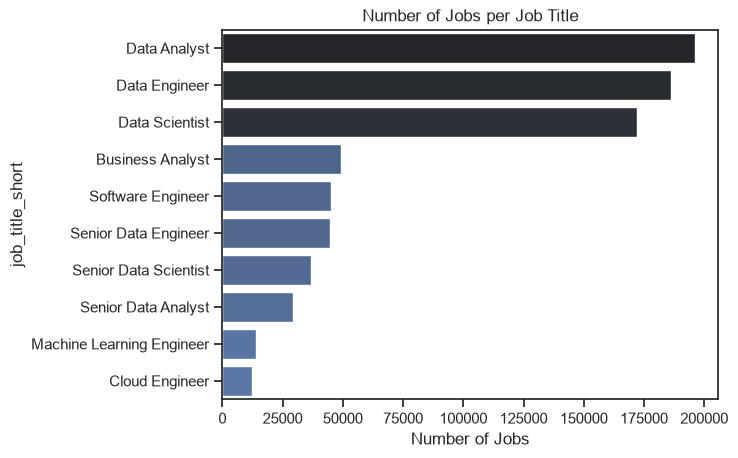

In [2]:
#Job titles Count
df_plot_roles=df['job_title_short'].value_counts().to_frame()
sns.set_theme(style='ticks')
sns.barplot(data=df_plot_roles, x='count',y='job_title_short',hue='count',legend=False,palette='dark:b_r')
#sns.color_palette("hls",3)
plt.title('Number of Jobs per Job Title')
plt.xlabel('Number of Jobs')
plt.show()

Countries to Explore

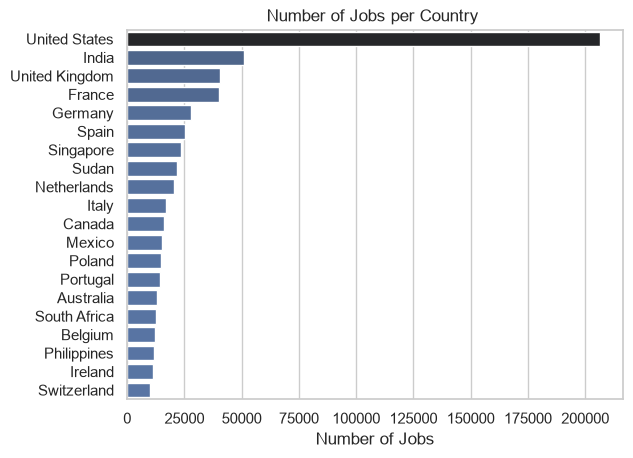

In [3]:
#Count of Countries 
df_plot_country=df['job_country'].value_counts().head(20).to_frame()

sns.set_theme(style='whitegrid')
sns.barplot(data=df_plot_country,x='count',y='job_country',hue='count',palette='dark:b_r',legend=False)
plt.title('Number of Jobs per Country ')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()


Companies to Explore

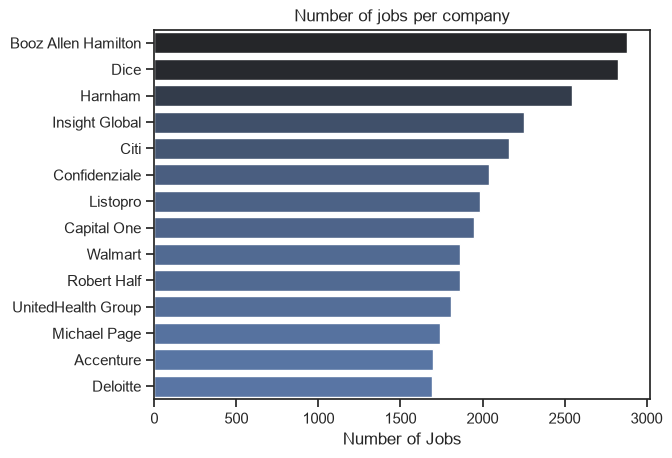

In [4]:
#Count of companies
df_plot_company=df['company_name'].value_counts().head(15).to_frame()[1:]
sns.set_theme(style='ticks')
sns.barplot(data=df_plot_company,x='count',y='company_name',hue='count',palette='dark:b_r',legend=False)
plt.title('Number of jobs per company')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

In [14]:
df_kenya=df[(df['job_country']=='Kenya')&(df['job_title_short']=='Data Analyst')]
df_kenya['job_location'].value_counts().head(20)

job_location
Nairobi, Kenya                472
Kenya                          48
Anywhere                        6
Thika, Kenya                    6
Eldoret, Kenya                  4
Kiambu, Kenya                   2
Kisumu, Kenya                   2
Bungoma, Kenya                  1
Nairobi, Kenya (+2 others)      1
Busia, Kenya                    1
Ruiru, Kenya                    1
Kenya  (+1 other)               1
Machakos, Kenya                 1
Mandera, Kenya                  1
Nakuru, Kenya                   1
Name: count, dtype: int64

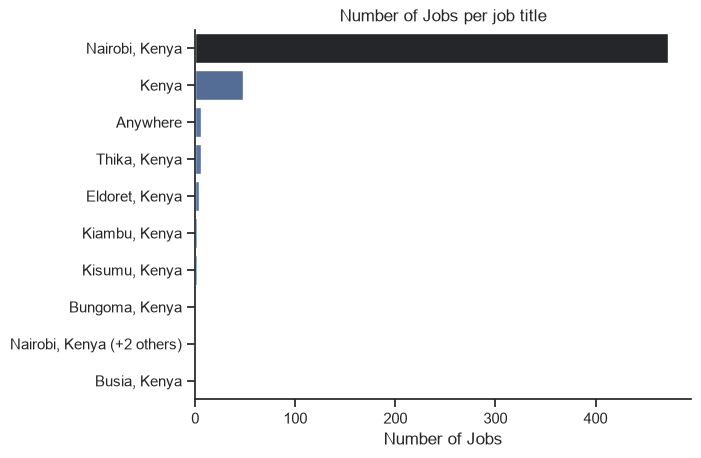

In [16]:
df_plot=df_kenya['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_plot,x='count',y='job_location',hue='count',palette='dark:b_r',legend=False)
sns.despine()
plt.title('Number of Jobs per job title')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

In [ ]:
df_DA_US=df[(df['job_country']=='United States')&(df['job_title_short']=='Data Analyst')]
df_DA_US

Exploratory Data Analysis for Data Analysts in the US

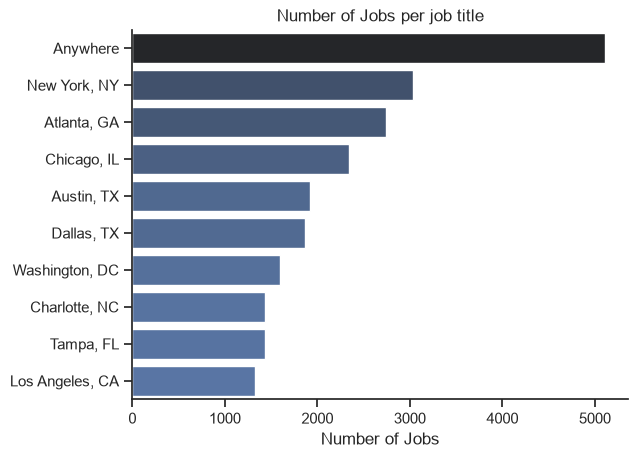

In [6]:
df_plot=df_DA_US['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_plot,x='count',y='job_location',hue='count',palette='dark:b_r',legend=False)
sns.despine()
plt.title('Number of Jobs per job title')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

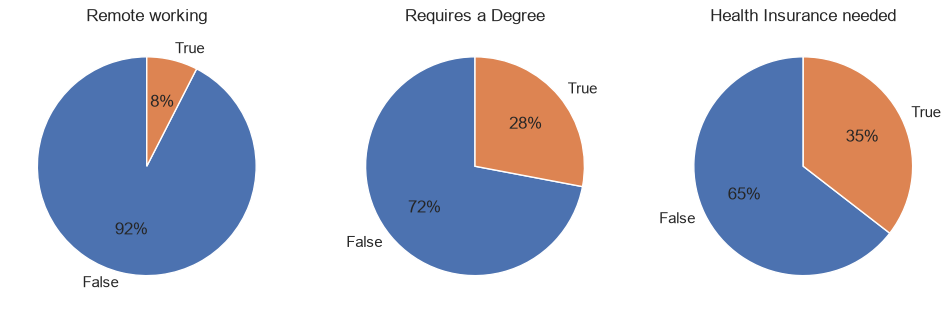

In [7]:

fig,ax=plt.subplots(1,3)
fig.set_size_inches(12,5)
#define a dictionary of the 3 colums
dict_column={
    'job_work_from_home':'Remote working',
    'job_no_degree_mention':'Requires a Degree',
    'job_health_insurance':'Health Insurance needed'
}

for i,(column,title) in enumerate(dict_column.items()):
    ax[i].pie(df_DA_US[column].value_counts(),startangle=90,autopct='%1.0f%%',labels=['False','True'])
    ax[i].set_title(title)

plt.show()

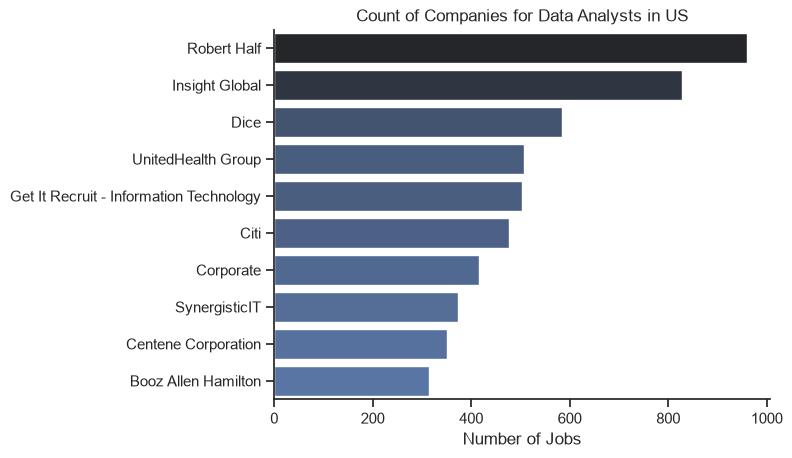

In [8]:
df_plot=df_DA_US['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data=df_plot,x='count',y='company_name',hue='count',palette='dark:b_r',legend=False)
sns.despine()
plt.title('Count of Companies for Data Analysts in US')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()